# Image variation in APTOS-2019

**Question.** How much do the APTOS-2019 photographs differ in resolution, framing, colour and sharpness, and does that variation line up with the diabetic-retinopathy (DR) grade?

**Why it matters.** A model that sees these images can learn *how the photo was taken* instead of *what the retina shows*. Before training any CNN we need to know how large the acquisition differences are and whether they are tied to the label.

| | |
|---|---|
| **Inputs** | `configs/splits/aptos_v1.csv` (frozen split manifest) and the raw PNG images under `data/raw/APTOS-2019/` |
| **Outputs** | `data/processed/aptos_development_image_metadata.csv` (git-ignored), figures in `reports/figures/` |
| **Rules** | Only **train** and **validation** images are opened. The sealed **test** partition is never decoded or profiled. APTOS has no patient IDs, so the split is image-level, not patient-level. |


**Reading guide.** Every section is: *what we do → code → observation → interpretation*. Observations that quote numbers come from the run  (split `aptos_v1`, seed 42) and from the saved metadata CSV; cells that print numbers recompute them.

# 0. Setup

One cell for imports and one for configuration. Everything that can change (paths, thresholds, rebuild switch) lives in the configuration cell.

In [39]:
%pip install -e ..


Obtaining file:///Users/arbazkhan/kael/Fundus_Biomarkers_DL
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for fundus (pyproject.toml) ... done
  Created wheel for fundus: filename=fundus-0.1.0-0.editable-py3-none-any.whl size=2088 sha256=78ac0d2e9ba7bd18c3584c21801884f926c5b796d6b408baaedbad8cba2828e1
  Stored in directory: /private/var/folders/t6/83ml_h093hb2vy010z1bgz_m0000gn/T/pip-ephem-wheel-cache-badjvuo3/wheels/17/9e/98/7c49b3e1c9634b75214421851bbf7f21cee6f91f1cd7ec9375
Successfully built fundus
  Attempting uninstall: fundus
    Found existing installation: fundus 0.1.0
    Uninstalling fundus-0.1.0:
      Successfully uninstalled fundus-0.1.0
Note: you may need to restart the kernel to use updated packages.


In [68]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from plotly.subplots import make_subplots
import plotly.graph_objects as go
from plotly.colors import qualitative


sns.set_theme(style="whitegrid", context="notebook")

# Locate the project root so the notebook works from the repo root or from notebooks/.
PROJECT_ROOT = Path.cwd().resolve()

if not (PROJECT_ROOT / "src" / "fundus").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
    
if not (PROJECT_ROOT / "src" / "fundus").is_dir():
    raise FileNotFoundError("Could not find src/fundus; run from the project root or the notebooks/ folder.")

if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

# Import from Fundus dir
from fundus.features.image_metadata import FOV_COLUMNS, build_image_metadata # FOV : Field of View 
from fundus.features.shortcut import (
    ALL_WHOLE_IMAGE_FEATURES,
    FOV_FEATURES,
    GRADE_LABELS,
    GRADE_NAMES,
    MetadataPreprocessor,
    resolution_label,
)

In [41]:
# ---------------------------------------------------------------------------------------------------------
#                                          CONFIGURATION
# ---------------------------------------------------------------------------------------------------------


SEED = 42
BLACK_THRESHOLD = 10        # a pixel is "dark" if all RGB channels are <= this value
REBUILD_METADATA = False    # True: re-profile every image even if a current CSV exists
N_JOBS = 4                  # worker processes for profiling; set 1 if multiprocessing misbehaves

# Raw data directory 
DATA_ROOT = PROJECT_ROOT / "data" / "raw" / "APTOS-2019"

# Split data directory 
SPLIT_CSV = PROJECT_ROOT / "configs" / "splits" / "aptos_v1.csv"

# Metadata CSV path 
METADATA_CSV = PROJECT_ROOT / "data" / "processed" / "aptos_development_image_metadata.csv"

# Figure directory 
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"

# Image directories for train, validation, and test sets
IMAGE_DIRECTORIES = (
    DATA_ROOT / "train_images" / "train_images",
    DATA_ROOT / "val_images" / "val_images",
    DATA_ROOT / "test_images" / "test_images",
)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# relative path helper for printing paths in a way that doesn't reveal personal folder names
def rel(path):
    # Print project-relative paths so no personal folder names end up in saved notebook output.
    try:
        return str(Path(path).resolve().relative_to(PROJECT_ROOT))
    except ValueError:
        return Path(path).name

if not SPLIT_CSV.exists():
    raise FileNotFoundError(f"Split manifest not found: {rel(SPLIT_CSV)}. Run scripts/create_aptos_split.py first.")

print("Split manifest:   ", rel(SPLIT_CSV))
print("Metadata output:  ", rel(METADATA_CSV))
print("Figure directory: ", rel(FIGURE_DIR))

Split manifest:    configs/splits/aptos_v1.csv
Metadata output:   data/processed/aptos_development_image_metadata.csv
Figure directory:  reports/figures


## 1 · Select the development images

The split manifest assigns every labelled image to `train`, `val` or `test`. We keep only `train` and `val` (the *development* set). The number of test rows is shown for bookkeeping; test labels are never used here.

### 1.1 Import Split data

In [42]:
pd.read_csv(SPLIT_CSV)

,id_code,diagnosis,split
0,000c1434d8d7,2,val
1,001639a390f0,4,train
2,0024cdab0c1e,1,train
3,002c21358ce6,0,test
4,005b95c28852,0,val
...,...,...,...
3483,ffa47f6a7bf4,2,train
3484,ffc04fed30e6,0,train
3485,ffcf7b45f213,2,train
3486,ffd97f8cd5aa,0,val


### 1.2 Data set distribution over split 

In [43]:
# Import the split manifest and select only the development rows (train + val). The test rows are excluded from all analysis below.

split_table = pd.read_csv(SPLIT_CSV, usecols=["id_code", "diagnosis", "split"])
split_table["id_code"] = split_table["id_code"].astype(str)

assert split_table["id_code"].is_unique, "Duplicate image IDs in the split manifest"

# Development images are those in the train and validation sets. 
development_table = split_table[split_table["split"].isin(["train", "val"])].copy()
development_ids = set(development_table["id_code"])

split_by_id = development_table.set_index("id_code")["split"].to_dict()

display(split_table["split"].value_counts().rename("images").to_frame())
print(f"Development images: {len(development_ids):,}  (test rows are excluded from everything below)")

,images
split,
train,2438
val,525
test,525


Development images: 2,963  (test rows are excluded from everything below)


# 2  Build or load the image metadata table

`build_image_metadata` (in `src/fundus/features/image_metadata.py`) measures each image once and returns two groups of columns:

* **Whole-image measurements** (original definitions): size, aspect ratio, file size, colour statistics over *all* pixels, native-resolution Laplacian variance, dark-pixel fraction.

* **Field-of-view (`fov_*`) measurements** (new): the retinal disc is detected, then colour statistics and sharpness are computed *inside the disc* on a copy resized to 512 px. These are not mechanically tied to the amount of black border or to the native pixel count.

**Why add the second group?** In the first run, brightness and colour means were averaged over black border pixels, and the Laplacian variance was computed at native resolution. Both are therefore partly *proxies for framing and resolution* rather than independent measurements. Section 6 quantifies this.

The cell below profiles the images only when the saved CSV is missing, stale (no `fov_*` columns) or `REBUILD_METADATA=True`.

### 2.1 Check for Metadata file 

In [44]:
def metadata_is_current():
    
    if not METADATA_CSV.exists():
        return False
    saved_columns = set(pd.read_csv(METADATA_CSV, nrows=0).columns)
    return set(FOV_COLUMNS) <= saved_columns

need_build = REBUILD_METADATA or not metadata_is_current()
print("Profile images now:" , need_build, "(missing/stale CSV or REBUILD_METADATA=True)" if need_build else "(current CSV found; it will be loaded)")

Profile images now: False (current CSV found; it will be loaded)


### 2.2 Make or Import Metadata 

In [45]:
if need_build:
    for image_directory in IMAGE_DIRECTORIES:
        if not image_directory.is_dir():
            raise FileNotFoundError(f"Image directory does not exist: {rel(image_directory)}")

    # The regenerated split can assign an image from any source folder to any partition, so index all folders.
    image_by_id = {}
    for image_directory in IMAGE_DIRECTORIES:
        for image_path in sorted(image_directory.glob("*.png")):
            if image_path.stem in image_by_id:
                raise ValueError(f"Image ID appears in more than one folder: {image_path.stem}")
            image_by_id[image_path.stem] = image_path

    missing_ids = sorted(development_ids - image_by_id.keys())
    if missing_ids:
        raise FileNotFoundError(f"{len(missing_ids)} development IDs have no PNG, e.g. {missing_ids[:5]}")

    development_paths = [image_by_id[image_id] for image_id in sorted(development_ids)]  # only dev images are opened
    metadata_df = build_image_metadata(
        development_paths, black_threshold=BLACK_THRESHOLD, on_error="skip",
        n_jobs=N_JOBS, show_progress=True,
    )
    failed_images = metadata_df.attrs.get("failed", [])
    if failed_images:
        display(pd.DataFrame(failed_images))
        raise RuntimeError("Some development images could not be read; resolve them before continuing.")

    metadata_df["source_folder"] = metadata_df["image_path"].map(lambda path: Path(path).parent.parent.name)
    METADATA_CSV.parent.mkdir(parents=True, exist_ok=True)
    metadata_df.to_csv(METADATA_CSV, index=False)
    print("Profiled and saved:", rel(METADATA_CSV))
    
else:
    metadata_df = pd.read_csv(METADATA_CSV)
    print("Loaded:", rel(METADATA_CSV))

# The manifest is authoritative for the partition; refresh it in case the CSV was built from an older split.
metadata_df["split"] = metadata_df["image_id"].map(split_by_id)
print(f"Rows: {len(metadata_df):,}   columns: {metadata_df.shape[1]}")

Loaded: data/processed/aptos_development_image_metadata.csv
Rows: 2,963   columns: 30


In [46]:
# This Metadata contains all two groups of information 
metadata_df.head(10) 

,image_id,image_path,width,height,aspect_ratio,file_size_bytes,brightness_mean,red_mean,green_mean,blue_mean,...,fov_brightness_mean,fov_red_mean,fov_green_mean,fov_blue_mean,fov_red_std,fov_green_std,fov_blue_std,fov_blur_laplacian_variance,source_folder,split
0,000c1434d8d7,/Users/arbazkhan/kael/Fundus_Biomarkers_DL/dat...,3216,2136,1.505618,3218676,51.388750,80.742828,43.169880,16.429441,...,68.154484,107.249214,57.305370,21.467049,21.800951,12.847187,3.558987,21.029886,val_images,val
1,001639a390f0,/Users/arbazkhan/kael/Fundus_Biomarkers_DL/dat...,3216,2136,1.505618,2261129,74.707307,128.786270,58.808113,14.365096,...,99.156101,171.091248,78.180466,18.567719,18.960793,9.267765,3.275599,11.461891,val_images,train
2,0024cdab0c1e,/Users/arbazkhan/kael/Fundus_Biomarkers_DL/dat...,2416,1736,1.391705,1882172,66.847439,117.739815,51.934376,9.767653,...,79.239495,139.718170,61.631439,11.248296,22.482994,13.287511,2.858004,22.054170,val_images,train
3,005b95c28852,/Users/arbazkhan/kael/Fundus_Biomarkers_DL/dat...,2048,1536,1.333333,1819430,22.645921,38.465210,18.830799,0.795823,...,47.586400,80.836182,39.573566,1.621112,24.706081,15.785147,5.602305,26.270950,val_images,val
4,0083ee8054ee,/Users/arbazkhan/kael/Fundus_Biomarkers_DL/dat...,3388,2588,1.309119,7401201,66.397845,93.385330,61.553558,20.410582,...,86.044794,121.097282,79.815300,26.174528,21.888693,13.391163,6.156480,27.666576,val_images,val
5,0097f532ac9f,/Users/arbazkhan/kael/Fundus_Biomarkers_DL/dat...,2588,1958,1.321757,5223375,49.541231,55.733955,46.763756,47.475842,...,49.520258,55.733463,46.762184,47.473949,22.092188,15.528240,12.506334,14.116865,val_images,val
6,00a8624548a9,/Users/arbazkhan/kael/Fundus_Biomarkers_DL/dat...,3216,2136,1.505618,2515726,74.169263,125.690666,60.054893,11.159502,...,98.428107,166.955566,79.853401,14.270709,21.132143,12.973625,3.168062,18.239515,val_images,val
7,00b74780d31d,/Users/arbazkhan/kael/Fundus_Biomarkers_DL/dat...,2588,1958,1.321757,5064447,48.885613,47.496990,50.049988,46.655697,...,53.054137,51.548206,54.334492,50.391708,19.946180,22.511688,21.516954,7.037529,val_images,train
8,00cb6555d108,/Users/arbazkhan/kael/Fundus_Biomarkers_DL/dat...,2416,1736,1.391705,2021665,65.385072,117.013176,50.437122,6.609593,...,77.497702,138.857925,59.835873,7.489629,23.072046,13.455523,3.356629,19.591059,val_images,train
9,00cc2b75cddd,/Users/arbazkhan/kael/Fundus_Biomarkers_DL/dat...,1050,1050,1.000000,901092,77.169665,132.605148,63.289513,3.460063,...,95.781659,164.599289,78.544624,4.125443,29.712051,19.360949,9.422621,45.152365,val_images,train


# 3 Data-quality checks

Before analysing anything: one row per image, exactly the development IDs, no missing measurements, plausible ranges.

### 3.1 Missing values and Metadata description

In [47]:
# Check that the metadata is consistent with the development manifest and contains only train/val rows.
assert metadata_df["image_id"].is_unique, "Metadata has repeated image IDs"
assert set(metadata_df["image_id"]) == development_ids, "Metadata IDs differ from the development IDs in the manifest"
assert set(metadata_df["split"]) == {"train", "val"}, "Development metadata must contain train and validation only"


FEATURES = ALL_WHOLE_IMAGE_FEATURES                                  # the 13 whole-image measurements
FOV = [column for column in FOV_FEATURES if column in metadata_df]   # field-of-view measurements, if present

eda_df = metadata_df.merge(
    development_table[["id_code", "diagnosis"]], left_on="image_id", right_on="id_code", validate="one_to_one"
).drop(columns="id_code")

# Add the diagnosis label to eda_df.
eda_df["grade"] = eda_df["diagnosis"].map(GRADE_NAMES)
eda_df["resolution"] = resolution_label(eda_df)

# Drop rows with missing values.
assert eda_df["diagnosis"].notna().all() and len(eda_df) == len(metadata_df)

# Missing values per column
missing_per_column = eda_df[FEATURES + FOV].isna().sum()

print("Missing measurements:", int(missing_per_column.sum()),
    "" if missing_per_column.sum() == 0 else missing_per_column[missing_per_column > 0].to_dict())
display(eda_df[FEATURES + FOV].describe().T.round(2))

Missing measurements: 0 


,count,mean,std,min,25%,50%,75%,max
width,2963.0,2005.23,891.83,474.00,1050.00,2048.00,2588.00,4288.00
height,2963.0,1527.77,546.58,358.00,1050.00,1536.00,1958.00,2848.00
aspect_ratio,2963.0,1.27,0.18,1.00,1.00,1.33,1.39,1.51
file_size_bytes,2963.0,2345687.91,1769745.45,221737.00,998816.50,1933981.00,2894402.00,7674292.00
brightness_mean,2963.0,66.89,18.14,14.97,51.88,69.37,81.12,129.62
red_mean,2963.0,105.55,31.44,29.29,76.62,112.48,131.34,216.76
green_mean,2963.0,56.47,15.76,10.55,44.60,57.58,67.92,121.90
blue_mean,2963.0,18.99,14.69,0.04,8.63,14.89,25.50,102.79
red_std,2963.0,60.84,15.59,14.97,49.82,65.06,71.99,100.17
green_std,2963.0,33.67,9.12,8.28,26.76,34.48,39.16,71.82


**Observation.**

The development set has 2,963 images (2,438 train, 525 validation) and no missing measurements. Widths range from 474 to 4,288 px and heights from 358 to 2,848 px, a nine-fold range in width. File size spans 0.2 to 7.7 MB. Brightness (grayscale mean over the whole image) runs from 15 to 130 on a 0–255 scale.

**Interpretation.** These ranges are much larger than the differences a clinician looks for in a retina. *The images were not taken under one protocol, and a single resize-and-normalise step will not make them comparable*. Rows with an FOV area near zero or `NaN` `fov_*` values (if any appear) are images where retina detection failed and should be inspected by eye, not dropped silently.

# 4 Class balance and representative images

First the label distribution, then one image per grade for visual context. The image panel is a fixed-seed sample, not a clinical review.

### 4.1 Label Distribution 

In [48]:
eda_df

,image_id,image_path,width,height,aspect_ratio,file_size_bytes,brightness_mean,red_mean,green_mean,blue_mean,...,fov_blue_mean,fov_red_std,fov_green_std,fov_blue_std,fov_blur_laplacian_variance,source_folder,split,diagnosis,grade,resolution
0,000c1434d8d7,/Users/arbazkhan/kael/Fundus_Biomarkers_DL/dat...,3216,2136,1.505618,3218676,51.388750,80.742828,43.169880,16.429441,...,21.467049,21.800951,12.847187,3.558987,21.029886,val_images,val,2,Moderate,3216x2136
1,001639a390f0,/Users/arbazkhan/kael/Fundus_Biomarkers_DL/dat...,3216,2136,1.505618,2261129,74.707307,128.786270,58.808113,14.365096,...,18.567719,18.960793,9.267765,3.275599,11.461891,val_images,train,4,Proliferative,3216x2136
2,0024cdab0c1e,/Users/arbazkhan/kael/Fundus_Biomarkers_DL/dat...,2416,1736,1.391705,1882172,66.847439,117.739815,51.934376,9.767653,...,11.248296,22.482994,13.287511,2.858004,22.054170,val_images,train,1,Mild,2416x1736
3,005b95c28852,/Users/arbazkhan/kael/Fundus_Biomarkers_DL/dat...,2048,1536,1.333333,1819430,22.645921,38.465210,18.830799,0.795823,...,1.621112,24.706081,15.785147,5.602305,26.270950,val_images,val,0,No DR,2048x1536
4,0083ee8054ee,/Users/arbazkhan/kael/Fundus_Biomarkers_DL/dat...,3388,2588,1.309119,7401201,66.397845,93.385330,61.553558,20.410582,...,26.174528,21.888693,13.391163,6.156480,27.666576,val_images,val,4,Proliferative,3388x2588
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2958,ff8a0b45c789,/Users/arbazkhan/kael/Fundus_Biomarkers_DL/dat...,1844,1226,1.504078,892620,72.921550,110.124458,64.226173,19.361547,...,26.548653,36.850807,27.967546,14.490055,19.162921,test_images,train,4,Proliferative,1844x1226
2959,ffa47f6a7bf4,/Users/arbazkhan/kael/Fundus_Biomarkers_DL/dat...,3388,2588,1.309119,4018809,52.209651,91.299728,40.358448,10.634896,...,13.508204,23.957752,11.405460,2.997473,29.225052,test_images,train,2,Moderate,3388x2588
2960,ffc04fed30e6,/Users/arbazkhan/kael/Fundus_Biomarkers_DL/dat...,2048,1536,1.333333,1705204,20.917613,37.341473,16.593937,0.093951,...,0.148745,19.999535,12.383549,1.168620,29.731183,test_images,train,0,No DR,2048x1536
2961,ffcf7b45f213,/Users/arbazkhan/kael/Fundus_Biomarkers_DL/dat...,3216,2136,1.505618,2528117,70.080691,121.813118,55.576157,8.625353,...,10.932194,23.825718,17.275673,4.153843,15.950118,test_images,train,2,Moderate,3216x2136


In [49]:
# Class count w.r.t diagnosis
class_counts = eda_df.groupby(["diagnosis", "split"]).size().unstack(fill_value=0).reindex(GRADE_LABELS, fill_value=0)
class_counts["total"] = class_counts[["train", "val"]].sum(axis=1)
class_counts["%_of_development"] = (100 * class_counts["total"] / class_counts["total"].sum()).round(1)
display(class_counts.rename(index=GRADE_NAMES))




split,train,val,total,%_of_development
diagnosis,,,,
No DR,1256,270,1526,51.5
Mild,236,51,287,9.7
Moderate,645,138,783,26.4
Severe,117,26,143,4.8
Proliferative,184,40,224,7.6


### 4.2 Label Distribution plot 

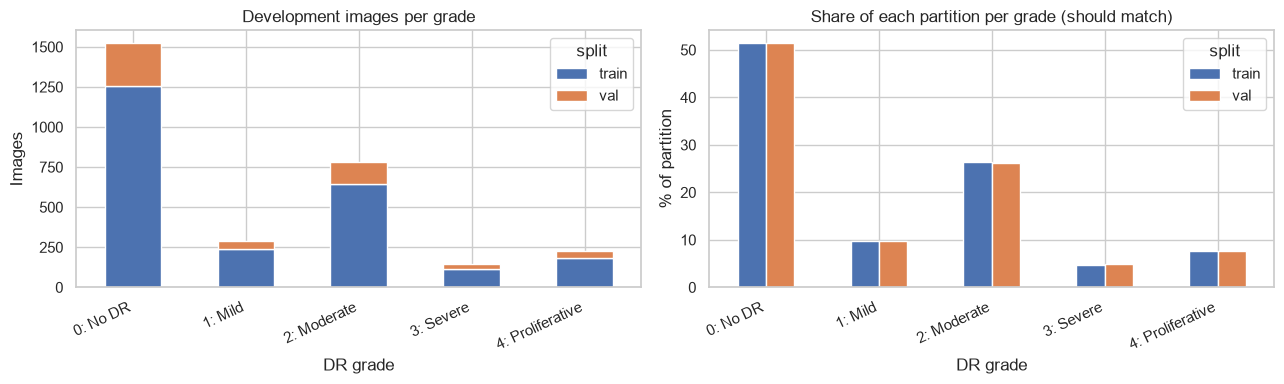

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

class_counts[["train", "val"]].plot(kind="bar", stacked=True, ax=axes[0], color=["#4C72B0", "#DD8452"])

axes[0].set(title="Development images per grade", xlabel="DR grade", ylabel="Images")

percent_within_split = 100 * class_counts[["train", "val"]] / class_counts[["train", "val"]].sum()
percent_within_split.plot(kind="bar", ax=axes[1], color=["#4C72B0", "#DD8452"])

axes[1].set(title="Share of each partition per grade (should match)", xlabel="DR grade", ylabel="% of partition")


for axis in axes:
    axis.set_xticklabels([f"{grade}: {GRADE_NAMES[grade]}" for grade in GRADE_LABELS], rotation=25, ha="right")
plt.tight_layout()
plt.show()

### 4.3 Visual context for DR grade

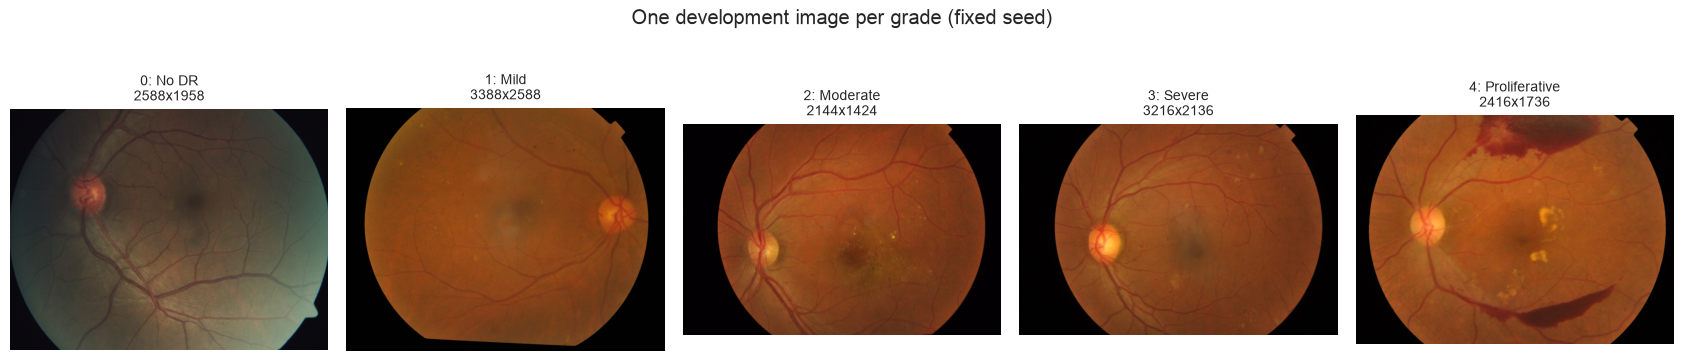

In [51]:
sample_rows = eda_df.groupby("diagnosis").sample(n=1, random_state=SEED).sort_values("diagnosis")

if not all(Path(path).exists() for path in sample_rows["image_path"]):
    print("Sample images are not on this machine at the saved paths; skipping the image panel.")
    
else:
    
    fig, axes = plt.subplots(1, len(sample_rows), figsize=(3.4 * len(sample_rows), 4.2))
    
    for axis, (_, row) in zip(np.atleast_1d(axes), sample_rows.iterrows()):
        with Image.open(row["image_path"]) as image:
            thumbnail = image.convert("RGB")
            thumbnail.thumbnail((700, 700))        # keep the plot light; the file is not modified
            
        axis.imshow(thumbnail)
        axis.set_title(f"{int(row['diagnosis'])}: {row['grade']}\n{row['resolution']}", fontsize=10)
        axis.axis("off")
        
        
    plt.suptitle("One development image per grade (fixed seed)")
    plt.tight_layout()
    plt.show()

**Observation.** 

- Grade 0 (No DR) is 1,526 of 2,963 images (51.5%); Moderate is 783 (26.4%); Mild 287 (9.7%); Proliferative 224 (7.6%); Severe 143 (4.8%). 

- The train and validation shares per grade agree to within about one percentage point, so the stratified split worked. The titles of the sample panel also show the exact resolution of each image; which is not same for all.

**Interpretation.** 

- Always predicting "No DR" already reaches about 51% accuracy, so accuracy alone is a poor yardstick; 

- we use quadratic weighted kappa (QWK, since grades are ordered), macro-F1 and balanced accuracy. Severe has only 26 validation images, so any per-grade number for it is very uncertain.

---

## Theory :  Quadratic Weighted Kappa (QWK)

**Quadratic Weighted Kappa (QWK)** is an evaluation metric used to measure the agreement between two raters (or a model's predictions and the ground truth labels) who rate ordinal items. Unlike standard Cohen's Kappa, which treats all disagreements equally, QWK penalizes larger discrepancies more heavily using a quadratic penalty function.



### 1. The Mathematical Formula

Quadratic Weighted Kappa is calculated using three matrices of size $N \times N$, where $N$ is the number of possible ratings (categories):

$$\kappa = 1 - \frac{\sum_{i,j} W_{i,j} O_{i,j}}{\sum_{i,j} W_{i,j} E_{i,j}}$$

#### Components of the Formula:
1. **$O_{i,j}$ (Observed Confusion Matrix):** 
   An $N \times N$ matrix where $O_{i,j}$ represents the number of times an item received rating $i$ from the first rater and rating $j$ from the second rater.

2. **$W_{i,j}$ (Weight Matrix):** 
   An $N \times N$ matrix that defines the penalty for disagreements. For quadratic weighting, it is calculated as:
   $$W_{i,j} = \frac{(i - j)^2}{(N - 1)^2}$$
   *Notice that if $i = j$ (perfect agreement), the weight is $0$. As the distance between $i$ and $j$ increases, the penalty increases quadratically.*

3. **$E_{i,j}$ (Expected Confusion Matrix):** 
   An $N \times N$ matrix calculating the expected agreement if the raters made their assignments completely at random. It is computed as the outer product of the two raters' marginal rating vectors, normalized by the total number of items:
   $$E_{i,j} = \frac{\text{Total Rater 1 ratings for } i \times \text{Total Rater 2 ratings for } j}{\text{Total number of items}}$$

---

### 2. Measurement Range and Interpretation

The value of Quadratic Weighted Kappa typically ranges from **$-1$ to $1$**, though theoretically, it can go below $-1$.

| QWK Value Range | Interpretation | Meaning |
| :--- | :--- | :--- |
| **$1.0$** | **Perfect Agreement** | The model/raters perfectly match the ground truth across all samples. |
| **$0.81$ to $0.99$** | **Almost Perfect** | Exceptionally high agreement; highly reliable predictions. |
| **$0.61$ to $0.80$** | **Substantial Agreement** | Strong correlation; standard benchmark for a "good" model in many tasks. |
| **$0.41$ to $0.60$** | **Moderate Agreement** | Acceptable agreement, but there is noticeable room for improvement. |
| **$0.21$ to $0.40$** | **Fair Agreement** | Slight positive relationship, but the predictions are weak. |
| **$0.01$ to $0.20$** | **Slight Agreement** | Barely better than random guessing. |
| **$0.0$** | **Random Agreement** | The agreement is exactly what would be expected by pure random chance. |
| **$< 0.0$** | **Less than Chance** | Systematic disagreement. The predictions are actively worse than random guessing. |

---

### 3. Why Use QWK Over Standard Accuracy or Unweighted Kappa?

* **Respects Ordinal Scale:** If actual score is `1` and a model predicts `2`, it is a minor mistake. If it predicts `5`, it is a major mistake. QWK captures this nuance, whereas standard accuracy and unweighted Kappa treat both mistakes as equally wrong.

* **Accounts for Random Guessing:** Like all Kappa variants, it corrects for the baseline probability of raters accidentally agreeing by chance.


# 5  Resolution structure and its link to the grade

Repeated exact resolutions usually mean different cameras or export pipelines. Here is the question that matters for modelling: **within each resolution, how are the grades distributed?** If a resolution is mostly one grade, then resolution is a label clue.

### 5.1 Resolution vs DR grad distribution

In [ ]:
# All possible resolution counts
resolution_counts = eda_df["resolution"].value_counts().rename("images").to_frame()

# Gradient Share for all resolutions 
grade_share = pd.crosstab(eda_df["resolution"], eda_df["diagnosis"], normalize="index").mul(100)

grade_share.columns = [f"% {GRADE_NAMES[column]}" for column in grade_share.columns]

resolution_table = resolution_counts.join(grade_share).round(1)

resolution_table["dominant grade %"] = grade_share.max(axis=1).round(1)
display(resolution_table)

single_grade_resolutions = resolution_table[resolution_table["dominant grade %"] >= 90]


print(f"{len(resolution_table)} distinct resolutions; {len(single_grade_resolutions)} of them are >=90% a single grade,")
print(f"covering {int(single_grade_resolutions['images'].sum()):,} of {len(eda_df):,} images "
      f"({100 * single_grade_resolutions['images'].sum() / len(eda_df):.1f}%).")

,images,% No DR,% Mild,% Moderate,% Severe,% Proliferative,dominant grade %
resolution,,,,,,,
1050x1050,829,93.2,1.9,4.0,0.0,0.8,93.2
2416x1736,500,3.4,34.6,40.2,9.2,12.6,40.2
2588x1958,460,44.6,8.5,29.8,8.0,9.1,44.6
3216x2136,311,0.6,3.2,74.6,8.7,12.9,74.6
2048x1536,291,100.0,0.0,0.0,0.0,0.0,100.0
819x614,239,96.7,2.9,0.4,0.0,0.0,96.7
3388x2588,120,0.0,10.0,63.3,4.2,22.5,63.3
1844x1226,49,0.0,18.4,46.9,2.0,32.7,46.9
4288x2848,45,0.0,31.1,22.2,8.9,37.8,37.8


17 distinct resolutions; 6 of them are >=90% a single grade,
covering 1,369 of 2,963 images (46.2%).


### 5.2 Grad Mix within Most common resolution 

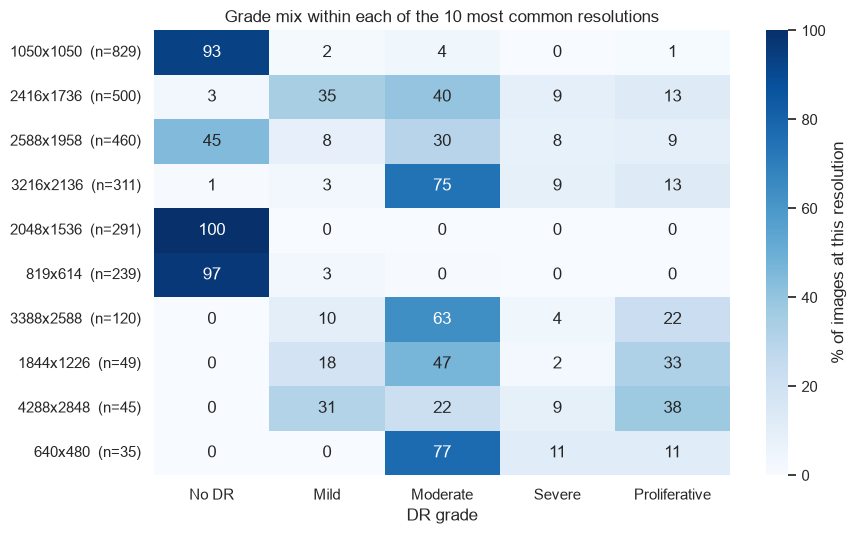

In [ ]:
# Top resolution 
top_resolutions = resolution_counts.head(10).index


heatmap_data = grade_share.loc[top_resolutions].rename(columns=lambda name: name.replace("% ", ""))
row_labels = [f"{resolution}  (n={resolution_counts.loc[resolution, 'images']})" for resolution in top_resolutions]

plt.figure(figsize=(9, 5.5))

sns.heatmap(heatmap_data.values, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100,
            xticklabels=heatmap_data.columns, yticklabels=row_labels, cbar_kws={"label": "% of images at this resolution"})


plt.title("Grade mix within each of the 10 most common resolutions")
plt.xlabel("DR grade")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "aptos_resolution_vs_grade_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

**Observation (the main finding of this notebook).** 

The 2,963 images come in 17 distinct resolutions and the grade mix differs sharply between them (rounded from the table above):

| Resolution | Images | Grade mix |
|---|---|---|
| 2048 × 1536 | 291 | 100% No DR (none of the 291 is diseased) |
| 819 × 614 | 239 | 97% No DR |
| 1050 × 1050 | 829 | 93% No DR |
| 2588 × 1958 | 460 | mixed: 45% No DR |
| 2416 × 1736 | 500 | mostly diseased: 3% No DR, 22% Severe or Proliferative |
| 3216 × 2136 | 311 | 75% Moderate, 0.6% No DR (2 images) |
| 3388 × 2588, 1844 × 1226, 4288 × 2848, 640 × 480 | 249 combined | no No-DR images at all |

Six of the 17 resolutions are at least 90% one grade, and together they cover 1,369 images (about 46% of total image).


**Interpretation.** 

The file looks like several image sources pooled together, each with its own camera, export size and *case mix*. 

**Consequences:**

1. Resolution alone is a strong hint for the label. Notebook 02 measures it: a plain lookup table "most common training grade at this resolution" reaches a validation QWK of about 0.59.

2. A CNN trained on a random split can score well partly by recognising the source, not the disease. Resizing every image to 224 or 512 pixels hides the pixel count but not the field-of-view shape, colour cast or noise pattern.

3. Only two large sources contain a real mix of grades (2588 × 1958 and 2416 × 1736, 960 images together). They are the natural base for a *source-matched* benchmark (see the conclusion).

# 6  How the measurements relate to the grade and to each other

We look at distributions by grade, a rank correlation of every measurement with the grade, and the correlations between measurements. The goal is to understand *what each measurement actually reflects* before using it as a feature.

### 6.1 Distribution by DR grade

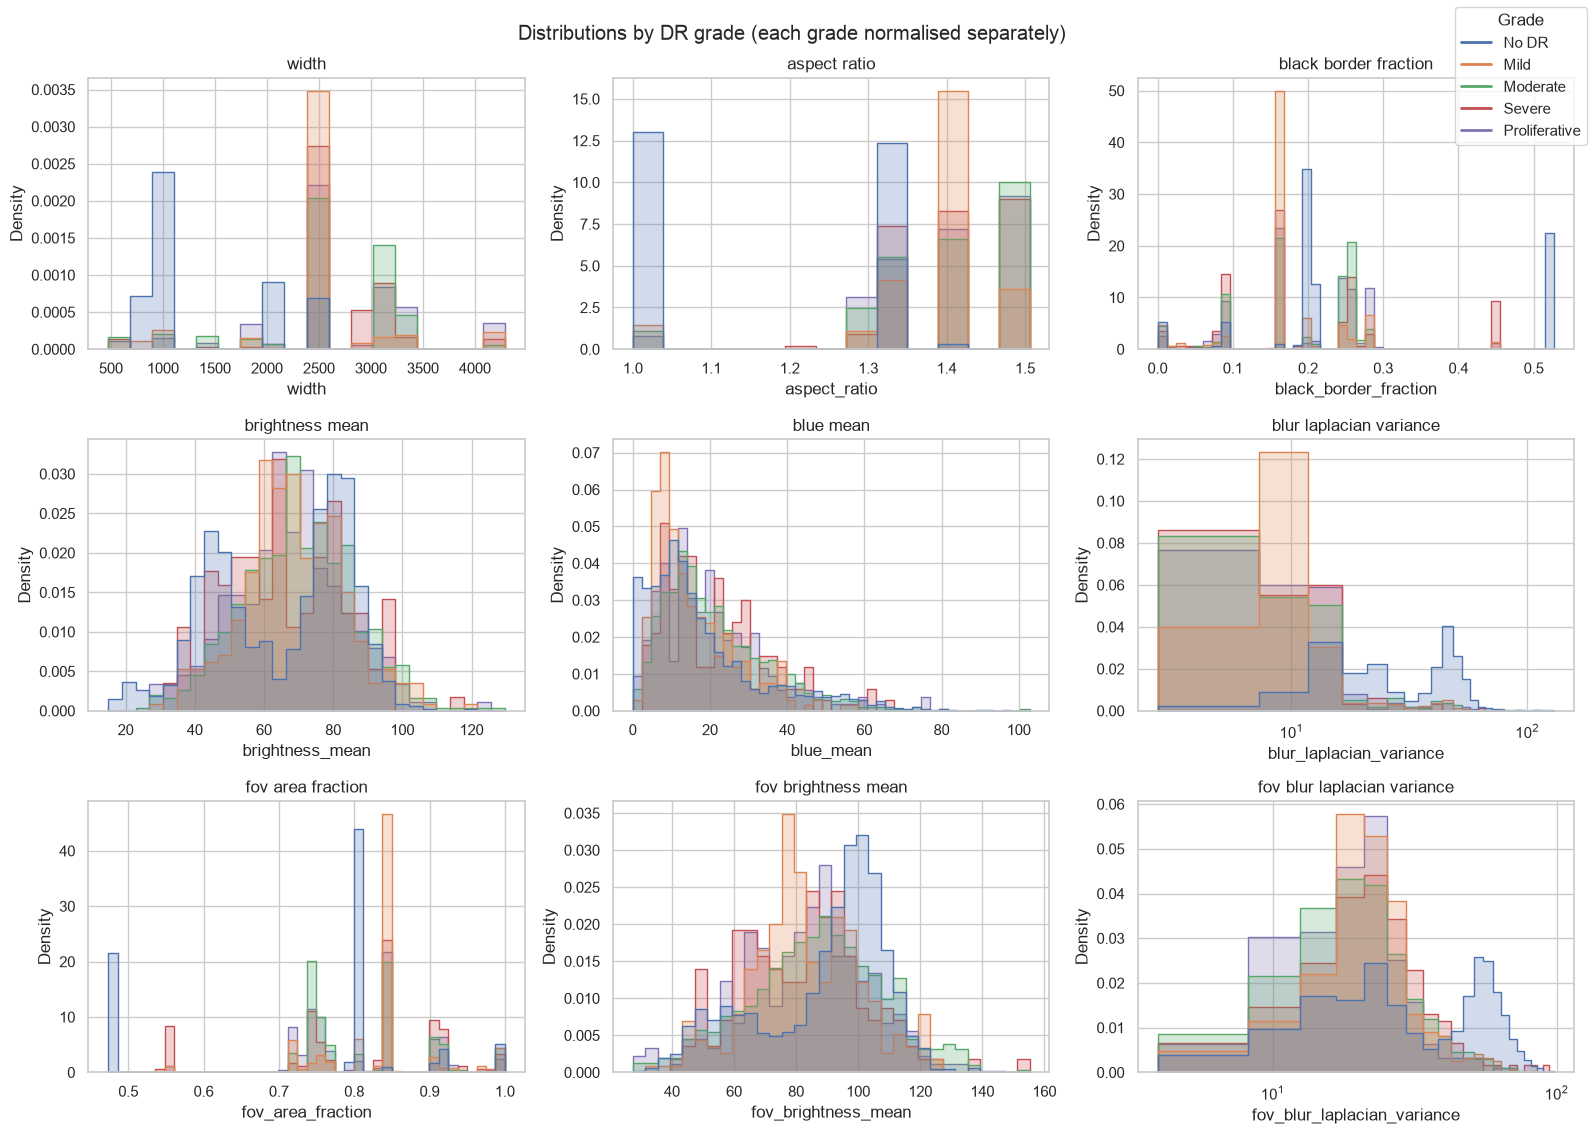

In [ ]:

# Selected Feature
distribution_features = ["width", "aspect_ratio", "black_border_fraction", "brightness_mean", "blue_mean",
                        "blur_laplacian_variance"] + [c for c in ["fov_area_fraction", "fov_brightness_mean",
                        "fov_blur_laplacian_variance"] if c in eda_df]

# Plot distribution
columns_per_row = 3
rows_needed = int(np.ceil(len(distribution_features) / columns_per_row))


fig, axes = plt.subplots(rows_needed, columns_per_row, figsize=(16, 3.8 * rows_needed))

for axis, feature in zip(axes.flat, distribution_features):
    
    sns.histplot(data=eda_df, x=feature, hue="grade", hue_order=[GRADE_NAMES[g] for g in GRADE_LABELS],
                element="step", stat="density", common_norm=False, ax=axis, legend=False)
    if "blur" in feature:
        axis.set_xscale("log")
    axis.set_title(feature.replace("_", " "))


for axis in list(axes.flat)[len(distribution_features):]:
    axis.axis("off")


handles = [plt.Line2D([0], [0], color=color, lw=2) for color in sns.color_palette(n_colors=5)]
fig.legend(handles, [GRADE_NAMES[g] for g in GRADE_LABELS], title="Grade", loc="upper right")
fig.suptitle("Distributions by DR grade (each grade normalised separately)")
plt.tight_layout()
plt.show()

## Theory :  Spearman's Rank Correlation Coefficient ($\rho$)

**Spearman's Rank Correlation Coefficient (Spearman's $\rho$ or $r_s$)** is a non-parametric measure of rank correlation. It assesses how well the relationship between two variables can be described using a monotonic function (whether linear or non-linear). Unlike Pearson's correlation, Spearman's coefficient evaluates the *ranks* of the data points rather than their raw numeric values.

---

## 1. The Mathematical Formula

The formula used depends on whether the data contains tied ranks (identical values).

### Case 1: When there are NO tied ranks
If all ranks are distinct, the formula simplifies to:

$$\rho = 1 - \frac{6 \sum d_i^2}{n(n^2 - 1)}$$

Where:
* $d_i = \text{rank}(X_i) - \text{rank}(Y_i)$ is the difference between the ranks of the corresponding values of the two variables for the $i$-th individual.
* $n$ is the total number of observations/data points.

### Case 2: When there ARE tied ranks
If tied ranks exist, the data points must be assigned average ranks, and Spearman's $\rho$ is calculated by applying the standard Pearson correlation formula directly to the converted ranks:

$$\rho = \frac{\sum (R(X_i) - \overline{R(X)})(R(Y_i) - \overline{R(Y)})}{\sqrt{\sum (R(X_i) - \overline{R(X)})^2 \sum (R(Y_i) - \overline{R(Y)})^2}}$$

Where:
* $R(X_i)$ and $R(Y_i)$ are the ranks of the $i$-th observation.
* $\overline{R(X)}$ and $\overline{R(Y)}$ are the mean ranks of the respective variables.

---

### 2. Measurement Range and Interpretation

Spearman's Rho ranges strictly from **$-1$ to $1$**.

| $\rho$ Value | Interpretation | Relationship Meaning |
| :--- | :--- | :--- |
| **$+1.0$** | **Perfect Positive Monotonic** | As $X$ increases, $Y$ always increases. The rank order matches exactly. |
| **$0.70$ to $0.99$** | **Strong Positive Monotonic** | High tendency for $Y$ to increase as $X$ increases, but not perfectly rigid. |
| **$0.30$ to $0.69$** | **Moderate Positive Monotonic**| A clear upward trend, though with notable scatter or variations. |
| **$0.01$ to $0.29$** | **Weak Positive Monotonic** | Very slight, negligible upward trend. |
| **$0.0$** | **No Monotonic Association** | Knowing the rank of $X$ tells you nothing about the rank of $Y$. |
| **$-0.01$ to $-0.29$** | **Weak Negative Monotonic** | Very slight, negligible downward trend. |
| **$-0.30$ to $-0.69$** | **Moderate Negative Monotonic**| A clear downward trend; as $X$ increases, $Y$ generally decreases. |
| **$-0.70$ to $-0.99$** | **Strong Negative Monotonic** | High tendency for $Y$ to decrease as $X$ increases. |
| **$-1.0$** | **Perfect Negative Monotonic** | As $X$ increases, $Y$ always decreases. The rank orders are perfectly inverted. |

---

### 3. Why Use Spearman's Rho Over Pearson's Correlation?

* **Handles Non-Linear Monotonic Relationships:** Pearson looks strictly for straight-line ($y = mx + c$) relationships. Spearman captures relationships where variables move together even if the rate of change is non-linear (e.g., exponential growth).

* **Robust to Outliers:** Because it converts raw numbers into sequential ranks ($1, 2, 3...$), extreme outlier data points have their leverage drastically reduced.

* **Works with Ordinal Data:** It can safely evaluate variables that are inherently ordered categories (e.g., movie ratings, satisfaction levels, competition placements) where true numerical distances between points do not exist.


### 6.2 Spearman's Rank

In [ ]:

rank_table = pd.DataFrame({
    "spearman_rho_with_grade": {feature: eda_df[feature].corr(eda_df["diagnosis"], method="spearman")
                                for feature in FEATURES + FOV if eda_df[feature].nunique() > 1},  # skip constant columns
}).sort_values("spearman_rho_with_grade", key=lambda values: values.abs(), ascending=False)

display(rank_table.round(2))

,spearman_rho_with_grade
blur_laplacian_variance,-0.65
width,0.63
height,0.60
aspect_ratio,0.57
fov_blue_std,-0.52
file_size_bytes,0.52
fov_blur_laplacian_variance,-0.41
fov_green_std,-0.32
fov_bbox_height_fraction,0.31
fov_red_std,-0.29


### 6.3 Spearman's Rank Plot 

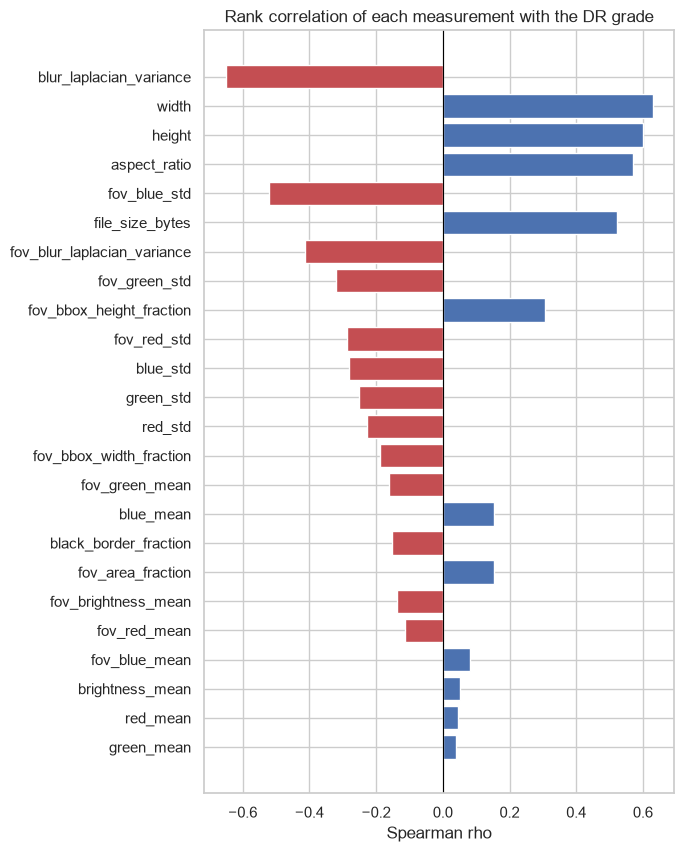

In [ ]:

plt.figure(figsize=(7, 0.32 * len(rank_table) + 1))
colors = ["#C44E52" if value < 0 else "#4C72B0" for value in rank_table["spearman_rho_with_grade"]]
plt.barh(rank_table.index[::-1], rank_table["spearman_rho_with_grade"][::-1], color=colors[::-1])


plt.axvline(0, color="black", lw=0.8)
plt.title("Rank correlation of each measurement with the DR grade")
plt.xlabel("Spearman rho")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "aptos_feature_grade_correlation.png", dpi=160, bbox_inches="tight")
plt.show()

**Observation (whole-image measurements, from the saved CSV).** 

- The strongest rank correlations with the grade are the framing/size measurements: width +0.63, height +0.60, aspect ratio +0.57, file size +0.52. 
- The native-resolution Laplacian variance is *negatively* related to the grade (−0.65). 
- The Colour means (brightness, red, green) are almost unrelated to the grade (|rho| ≤ 0.05); blue mean is +0.15, and the colour standard deviations are weakly negative (−0.23 to −0.28).

**Interpretation.** 

- Higher grades come from larger and wider images in this file. The negative blur correlation should **not** be read as "severe cases are blurrier": the Laplacian variance of a native-resolution image falls as the pixel count rises (rho with width is −0.74 in this data), so it mostly tracks image size. 

- This is why the `fov_blur_laplacian_variance` column (fixed 512 px, inside the retinal disc) is the better sharpness measure. If it shows a weaker relation to the grade than the native one in the table above, that confirms the point. If the `fov_*` rows are missing, the CSV is stale: set `REBUILD_METADATA=True`.

In [19]:
# Hold the resolution fixed: do the relationships survive inside the two large mixed-grade sources?
mixed_resolutions = [res for res in resolution_table.index
                     if resolution_table.loc[res, "images"] >= 300 and resolution_table.loc[res, "dominant grade %"] < 60][:2]
within_rows = {}
for resolution in mixed_resolutions:
    subset = eda_df[eda_df["resolution"] == resolution]
    within_rows[f"{resolution} (n={len(subset)})"] = {
        feature: subset[feature].corr(subset["diagnosis"], method="spearman")
        for feature in FEATURES + FOV if subset[feature].nunique() > 1
    }
within_table = pd.DataFrame(within_rows)
within_table["overall"] = rank_table["spearman_rho_with_grade"]
display(within_table.sort_values("overall", key=lambda values: values.abs(), ascending=False).round(2))

,2416x1736 (n=500),2588x1958 (n=460),overall
blur_laplacian_variance,0.03,-0.02,-0.65
fov_blue_std,0.11,-0.37,-0.52
file_size_bytes,0.10,-0.18,0.52
fov_blur_laplacian_variance,0.10,-0.17,-0.41
fov_green_std,0.17,-0.12,-0.32
fov_red_std,0.05,0.07,-0.29
blue_std,0.07,-0.33,-0.28
green_std,0.15,-0.05,-0.25
red_std,0.02,0.16,-0.23
fov_bbox_width_fraction,-0.01,NaN,-0.19


**Observation (whole-image measurements).** Inside the single resolution 2416 × 1736, every measurement is only weakly related to the grade (largest |rho| about 0.15). Inside 2588 × 1958 the blue-channel statistics keep a clear relation (blue mean −0.41, blue standard deviation −0.33, dark-pixel fraction +0.30). The overall width, height and file-size relations disappear, as they must, because those are nearly constant within one resolution.

**Interpretation.** Most of the strong overall relations come from *which source an image belongs to*, not from variation within a source. The blue-channel signal inside 2588 × 1958 is not explained by resolution. It could be a difference between sub-sources or processing pipelines at that same resolution, or a genuine appearance difference linked to disease. Metadata cannot separate these. Looking at images from the extremes of that blue-channel range is a cheap next step, ideally together with your clinical collaborator.

### 6.4 Correlation 

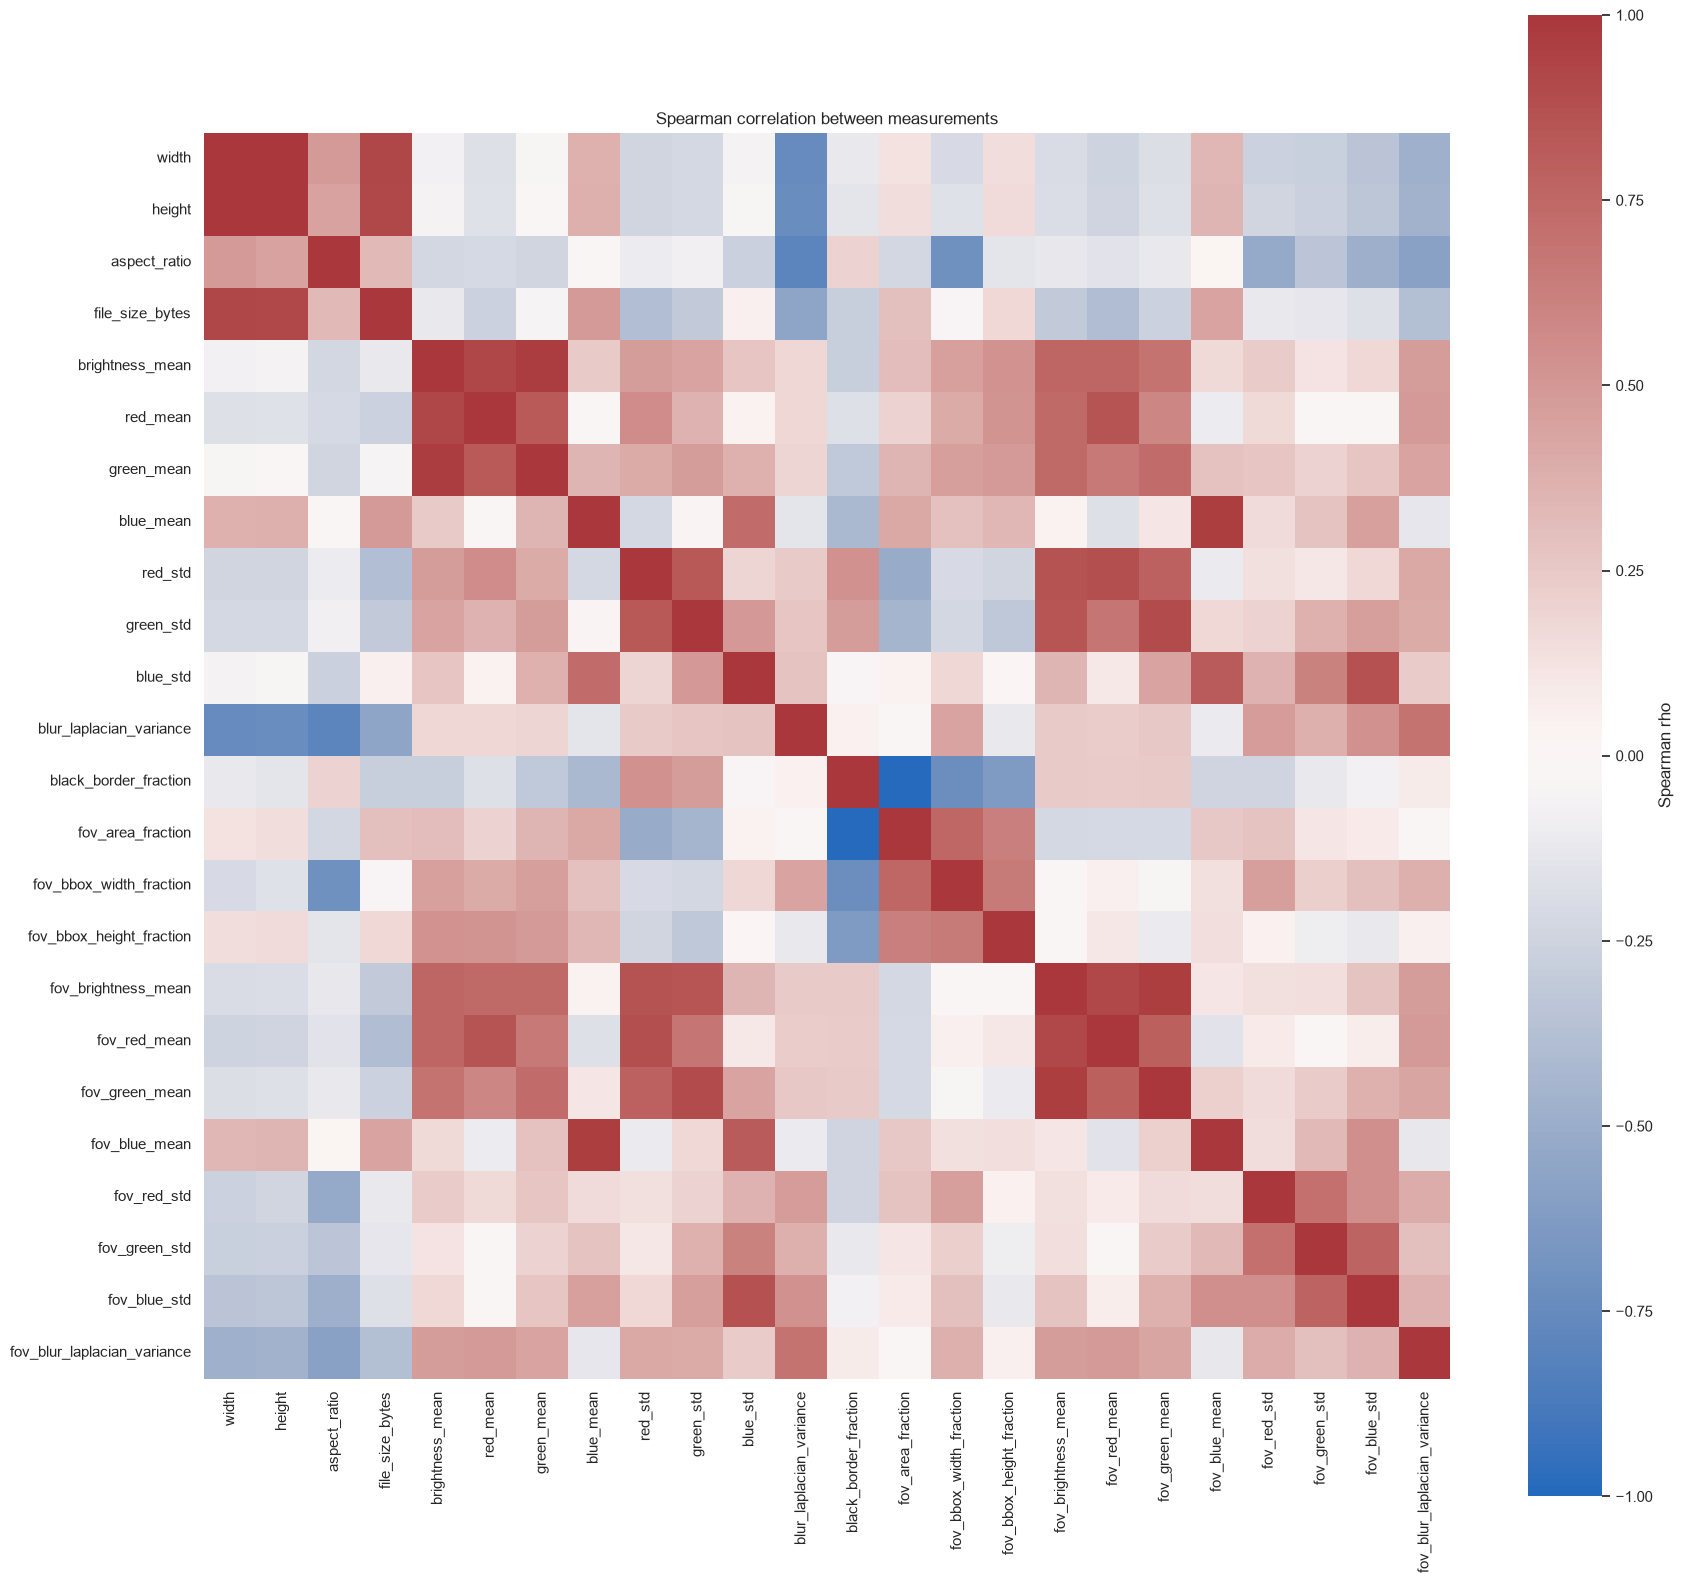

In [ ]:

correlation = eda_df[FEATURES + FOV].corr(method="spearman")


plt.figure(figsize=(0.62 * len(correlation) + 3, 0.6 * len(correlation) + 2))
sns.heatmap(correlation, cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"label": "Spearman rho"})
plt.title("Spearman correlation between measurements")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "aptos_metadata_correlation.png", dpi=160, bbox_inches="tight")
plt.show()


### 6.5 Pair wise Spearman's rank

In [58]:
pairs_of_interest = [
    ("blur_laplacian_variance", "width", "native sharpness vs pixel count"),
    ("black_border_fraction", "aspect_ratio", "border vs aspect ratio"),
    ("brightness_mean", "black_border_fraction", "whole-image brightness vs border"),
    ("blue_mean", "black_border_fraction", "whole-image blue mean vs border"),
    ("fov_blur_laplacian_variance", "width", "FOV sharpness vs pixel count"),
    ("fov_brightness_mean", "black_border_fraction", "FOV brightness vs border"),
    ("fov_blue_mean", "black_border_fraction", "FOV blue mean vs border"),
]
rows = [{"pair": label, "spearman_rho": correlation.loc[a, b]} for a, b, label in pairs_of_interest
        if a in correlation and b in correlation]
display(pd.DataFrame(rows).round(2))

,pair,spearman_rho
0,native sharpness vs pixel count,-0.74
1,border vs aspect ratio,0.20
2,whole-image brightness vs border,-0.28
3,whole-image blue mean vs border,-0.42
4,FOV sharpness vs pixel count,-0.48
5,FOV brightness vs border,0.25
6,FOV blue mean vs border,-0.25


**Observation.**

- Whole-image measurements are partly tied to framing and size: native Laplacian variance vs width −0.74, whole-image blue mean vs dark-border fraction −0.42, whole-image brightness vs border −0.28, border fraction vs aspect ratio +0.20 (weak, because the 829 square images have little border). 

- The last three rows of the table (the FOV versions) show how much of this tie disappears once statistics are taken inside the retinal disc at a fixed size.

**Interpretation.** 

- Decision rule for later notebooks: where a `fov_*` measurement exists, prefer it to its whole-image twin when the question is about *image content*, and keep the whole-image versions only to describe the files as stored. If the FOV correlations with width and border are close to zero, the new measurements are doing their job.

# 7  Outliers

A value outside 1.5 × IQR is not necessarily an error. Here the check is mainly to see *how many* images fall outside and on which measurements. Counts use training rows only; file size and Laplacian variance are log-transformed first because they are strongly skewed.

In [60]:

train_frame = eda_df.loc[eda_df["split"] == "train", FEATURES].astype(float).copy()


for column in ["file_size_bytes", "blur_laplacian_variance"]:
    train_frame[column] = np.log1p(train_frame[column])

# quantiles 
q1, q3 = train_frame.quantile(0.25), train_frame.quantile(0.75)
iqr = q3 - q1

# outlier counts 
outlier_counts = ((train_frame < q1 - 1.5 * iqr) | (train_frame > q3 + 1.5 * iqr)).sum()


display(outlier_counts.rename("train rows outside 1.5 x IQR").sort_values(ascending=False).to_frame())
print(f"Training rows: {len(train_frame):,}")

,train rows outside 1.5 x IQR
black_border_fraction,509
blue_mean,114
blue_std,45
green_std,17
green_mean,5
red_std,4
brightness_mean,1
red_mean,1
width,0
height,0


Training rows: 2,438


**Observation.** 

- Dark-pixel fraction has 509 of 2,438 training rows outside the IQR fences (21%), blue mean 114, blue standard deviation 45, green standard deviation 17, green mean 5, red standard deviation 4, brightness and red mean 1 each. Width, height, aspect ratio, file size and Laplacian variance have none.

**Interpretation.** 

- 509 "outliers" in one measurement is not a handful of bad images. It is a distribution with several clusters (square tightly-cropped photos with almost no border versus wide photos with large black margins). 

- The IQR rule is applied to a mixture and flags the minority clusters. Decision: **do not delete or cap images because of these counts**; the unusual values are real differences in acquisition. Capping at fit-time percentiles is still applied inside the models in notebook 02, where it is fitted on training folds only.

## 8 · PCA: what is the dominant structure in the metadata?

PCA is used for one purpose: to see whether the main axes of variation in the measurements follow **resolution/source** or **grade**. The scaler and components are fitted on training rows only and validation rows are projected onto them. The picture is descriptive and is not a classification result.

### 8.1 2D

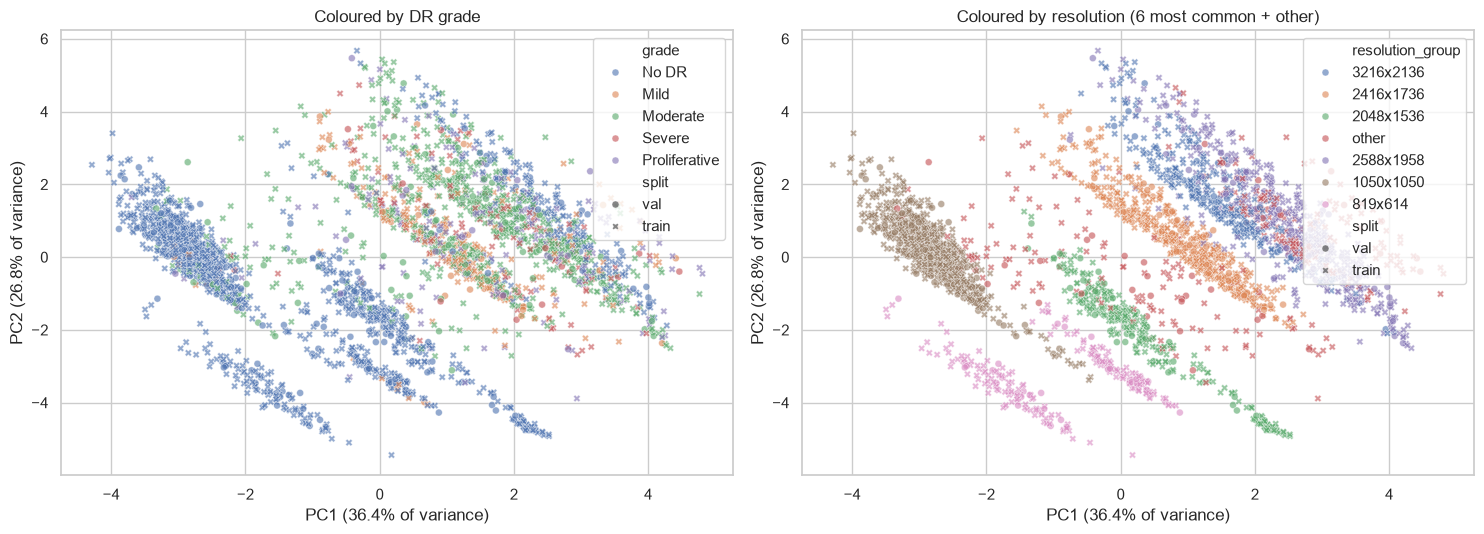

Variance explained by PC1+PC2: 63.2%
PC1: share of variance explained by resolution group = 0.79; by grade = 0.30
PC2: share of variance explained by resolution group = 0.54; by grade = 0.12


In [61]:

# Selected features
pca_features = FEATURES  # the 13 whole-image measurements, as in the first analysis
train_mask = eda_df["split"].eq("train").to_numpy()


preprocessor = MetadataPreprocessor(feature_names=pca_features).fit(eda_df.loc[train_mask, pca_features])
scaler = StandardScaler().fit(preprocessor.transform(eda_df.loc[train_mask, pca_features]))


# Apply PCA
pca = PCA(n_components=2, random_state=SEED).fit(scaler.transform(preprocessor.transform(eda_df.loc[train_mask, pca_features])))
components = pca.transform(scaler.transform(preprocessor.transform(eda_df[pca_features])))
eda_df["PC1"], eda_df["PC2"] = components[:, 0], components[:, 1]

# Extract Top 6
top_six = resolution_counts.head(6).index
eda_df["resolution_group"] = eda_df["resolution"].where(eda_df["resolution"].isin(top_six), "other")


def eta_squared(values, groups):
    # Share of the variance of `values` that is explained by group membership (0 to 1).
    values = pd.Series(np.asarray(values)).reset_index(drop=True)
    groups = pd.Series(np.asarray(groups)).reset_index(drop=True)
    grand_mean = values.mean()
    between = sum(len(part) * (part.mean() - grand_mean) ** 2 for _, part in values.groupby(groups))
    return between / ((values - grand_mean) ** 2).sum()


fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.scatterplot(data=eda_df, x="PC1", y="PC2", hue="grade", hue_order=[GRADE_NAMES[g] for g in GRADE_LABELS],
                style="split", alpha=0.6, s=25, ax=axes[0])
axes[0].set_title("Coloured by DR grade")

sns.scatterplot(data=eda_df, x="PC1", y="PC2", hue="resolution_group", style="split", alpha=0.6, s=25, ax=axes[1])
axes[1].set_title("Coloured by resolution (6 most common + other)")


for axis in axes:
    axis.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
    axis.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")



plt.tight_layout()
plt.savefig(FIGURE_DIR / "aptos_metadata_pca_by_grade_and_resolution.png", dpi=160, bbox_inches="tight")
plt.show()

print(f"Variance explained by PC1+PC2: {pca.explained_variance_ratio_.sum():.1%}")
for name in ["PC1", "PC2"]:
    print(f"{name}: share of variance explained by resolution group = {eta_squared(eda_df[name], eda_df['resolution_group']):.2f}; "
        f"by grade = {eta_squared(eda_df[name], eda_df['diagnosis']):.2f}")

**Observation.** 

The first two components retain 63.2% of the variance (PC1 36.4%, PC2 26.8%). Resolution group explains 79% of the variance of PC1 and 54% of PC2; the grade explains 30% of PC1 and 12% of PC2.

**Interpretation.** 

The main structure in the measurements is *which kind of image it is*, with the grade a distant second. Points of one grade are spread over several resolution clusters instead of forming a grade cluster of their own. 

### 8.2 3D

In [ ]:

pca_features = FEATURES
train_mask = eda_df["split"].eq("train").to_numpy()

preprocessor = MetadataPreprocessor(feature_names=pca_features).fit(
    eda_df.loc[train_mask, pca_features]
)
train_scaled = StandardScaler().fit(
    preprocessor.transform(eda_df.loc[train_mask, pca_features])
)
pca = PCA(n_components=3, random_state=SEED).fit(
    train_scaled.transform(preprocessor.transform(eda_df.loc[train_mask, pca_features]))
)
components = pca.transform(
    train_scaled.transform(preprocessor.transform(eda_df[pca_features]))
)
eda_df[["PC1", "PC2", "PC3"]] = components

# Normalize grade codes before mapping so values like 0.0 map to grade 0.
grade_codes = pd.to_numeric(eda_df["diagnosis"], errors="coerce")
invalid_grades = grade_codes.isna() | ~grade_codes.isin(GRADE_LABELS)
if invalid_grades.any():
    raise ValueError(
        f"Unexpected diagnosis values: "
        f"{eda_df.loc[invalid_grades, 'diagnosis'].unique().tolist()}"
    )

eda_df["grade_plot"] = grade_codes.astype(int).map(GRADE_NAMES)
grade_order = [GRADE_NAMES[grade] for grade in GRADE_LABELS]

top_six = resolution_counts.head(6).index.tolist()
eda_df["resolution_group"] = eda_df["resolution"].where(
    eda_df["resolution"].isin(top_six), "other"
)
resolution_order = top_six + ["other"]

split_values = [
    split for split in ("train", "val", "validation")
    if eda_df["split"].eq(split).any()
]
if not split_values:
    raise ValueError("No train or validation rows found for the PCA plot.")

symbol_map = {"train": "circle", "val": "diamond", "validation": "diamond"}
color_sequence = qualitative.Plotly

print("Grades found:", eda_df["grade_plot"].value_counts().to_dict())
print("Grades missing from data:", set(grade_order) - set(eda_df["grade_plot"]))

fig = make_subplots(
    rows=1,
    cols=2,
    specs=[[{"type": "scene"}, {"type": "scene"}]],
    subplot_titles=("DR grade", "Image resolution"),
)

panels = [
    (1, "grade_plot", grade_order, "Grade"),
    (2, "resolution_group", resolution_order, "Resolution"),
]

for col, group_column, group_order, legend_prefix in panels:
    for group_index, group in enumerate(group_order):
        label_added = False

        for split in split_values:
            subset = eda_df[
                eda_df[group_column].eq(group) & eda_df["split"].eq(split)
            ]
            if subset.empty:
                continue

            fig.add_trace(
                go.Scatter3d(
                    x=subset["PC1"],
                    y=subset["PC2"],
                    z=subset["PC3"],
                    mode="markers",
                    name=f"{legend_prefix}: {group}",
                    legendgroup=f"{col}-{group}",
                    showlegend=not label_added,
                    marker=dict(
                        color=color_sequence[group_index % len(color_sequence)],
                        symbol=symbol_map[split],
                        size=4,
                        opacity=0.6,
                    ),
                    hovertemplate=(
                        "PC1=%{x:.3f}<br>PC2=%{y:.3f}<br>PC3=%{z:.3f}<br>"
                        f"{group_column}={group}<br>split={split}<extra></extra>"
                    ),
                ),
                row=1,
                col=col,
            )
            label_added = True

axis_titles = (
    f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)",
    f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)",
    f"PC3 ({pca.explained_variance_ratio_[2]:.1%} variance)",
)
for col in (1, 2):
    fig.update_scenes(
        xaxis_title=axis_titles[0],
        yaxis_title=axis_titles[1],
        zaxis_title=axis_titles[2],
        row=1,
        col=col,
    )

fig.update_layout(
    width=1500,
    height=800,
    title=dict(
        text=(
            "3D Metadata PCA by grade and resolution"
            "<br><sup>Marker shape: train = circle; validation = diamond</sup>"
        )
    ),
    legend=dict(
        title_text="Color group",
        orientation="h",
        x=0.5,
        xanchor="center",
        y=-0.18,
        yanchor="top",
    ),
    margin=dict(b=170),
)

fig.write_html(FIGURE_DIR / "aptos_metadata_pca_3d_by_grade_and_resolution.html")
fig.show()

print(f"Variance explained by PC1+PC2+PC3: {pca.explained_variance_ratio_.sum():.1%}")

Grades found: {'No DR': 1526, 'Moderate': 783, 'Mild': 287, 'Proliferative': 224, 'Severe': 143}
Grades missing from data: set()


Variance explained by PC1+PC2+PC3: 79.1%


## 9 · Summary, decisions and what comes next

### Findings

1. **The development set is a pool of at least 17 resolution families**, in which resolution is strongly linked to the grade: 6 resolutions covering 46% of the images are at least 90% one grade (2048 × 1536 is 100% No DR). Section 5.

2. **Metadata is dominated by source, not by grade**: resolution explains 79% of the first principal component against 30% for grade. Section 8.

3. **Several measurements are not independent descriptions of image content**: native sharpness follows pixel count (rho −0.74) and whole-image colour statistics follow the amount of black border. Section 6. The new `fov_*` measurements are designed to avoid both effects; check the printed correlations.

4. **Within a source the picture is mixed**: almost no relation to the grade inside 2416 × 1736, a persistent blue-channel relation inside 2588 × 1958. Section 6.

5. **The class distribution is imbalanced** (No DR 51.5%, Severe 4.8%), so accuracy is not an adequate metric.

### Decisions for the modelling phase

* **Do not trust a headline score from a random split of this pool.** Also report results *per resolution group*.

* Build a **source-matched benchmark** from the two mixed-grade sources (2588 × 1958 and 2416 × 1736, 960 images) and compare it with the all-data result. The gap is a measure of how much a model profits from the source.

* Preprocess every image the same way (crop to the retinal disc, pad to a square, resize to a fixed size, per-image colour normalisation) and **re-run this metadata analysis on the preprocessed images** to see how much of the signal remains.

* Treat the cross-dataset test (train on one dataset, test on another) as the main evidence for generalisation, not the random split.

* Look at images from the extremes of the blue-channel range inside 2588 × 1958 with your clinical collaborator.

* Confirm from the dataset documentation which clinics and cameras the file comes from.

### Limits of this notebook

Metadata describes files, not retinas; relations here are associations, not proof that a CNN uses them. There are no patient IDs, so images of the same person may sit in different partitions. The sealed test partition was not opened.

**Next:** `02_metadata_shortcut_test.ipynb` measures how well these measurements predict the grade.